In [183]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

pd.set_option("display.max_columns", None)

In [184]:
DATA_PATH = "../data/telco_customer_churn.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [185]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [186]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [187]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


customerID:
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                

C:\Users\Emine Bilge\AppData\Local\Temp\ipykernel_13112\4209309778.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [188]:
df.nunique().sort_values()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64

In [189]:
blank_total_charges = df["TotalCharges"].str.strip().eq("")

blank_total_charges.sum()

np.int64(11)

In [190]:
df.loc[
    blank_total_charges,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [191]:
zero_tenure=df["tenure"].eq(0)
zero_tenure.sum()

np.int64(11)

TotalCharges kolonunda boş değere sahip olan müşterilerin tamamında tenure değerinin 0 olduğu görülmüştür. Aynı şekilde tenure kolonunda 0 değerine sahip olan müşterilerin tamamında TotalCharges değerinin boş olduğu göürülmüştür. Bu müşteriler henüz ilk ayını tamamlamadığı için toplam ödeme bilgileri oluşmamış olabilir.

In [192]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [193]:
new_customer_missing = (
    df["TotalCharges"].isna()
    & df["tenure"].eq(0)
)

df.loc[new_customer_missing, "TotalCharges"] = 0

df.loc[
    zero_tenure,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No


In [194]:
print("Tekrarlanan satır sayısı:", df.duplicated().sum())
print(
    "Tekrarlanan müşteri kimliği sayısı:",
    df["customerID"].duplicated().sum()
)

Tekrarlanan satır sayısı: 0
Tekrarlanan müşteri kimliği sayısı: 0


Veri setinde tamamen tekrarlanan satırlar ve tekrarlanan müşteri kimlikleri kontrol edildi. Her satırın farklı bir müşteriyi temsil ettiği doğrulandı.

In [195]:
missing_values = df.isna().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [196]:
churn_counts = df["Churn"].value_counts()

churn_percentages = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(churn_counts)
print(churn_percentages)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


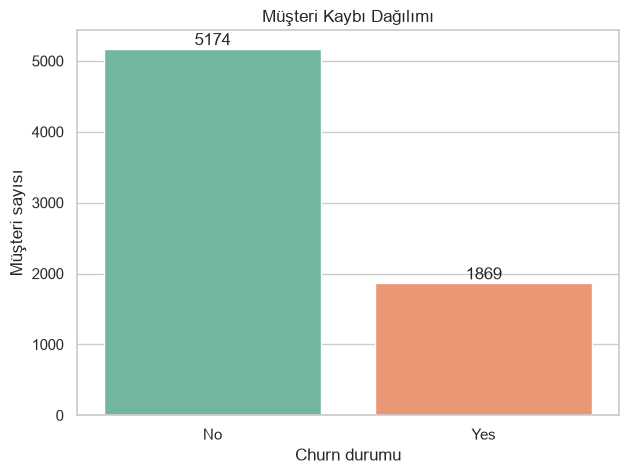

In [197]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Müşteri Kaybı Dağılımı")
plt.xlabel("Churn durumu")
plt.ylabel("Müşteri sayısı")
plt.show()

Müşterilerin yaklaşık %73'ü aboneliğine devam ederken %27'si aboneliğini iptal etmiş. Sınıfların tam dengeli olmaması nedeniyle model ,çoğunluk sınıfı olan No tahminine daha fazla yönelebilir

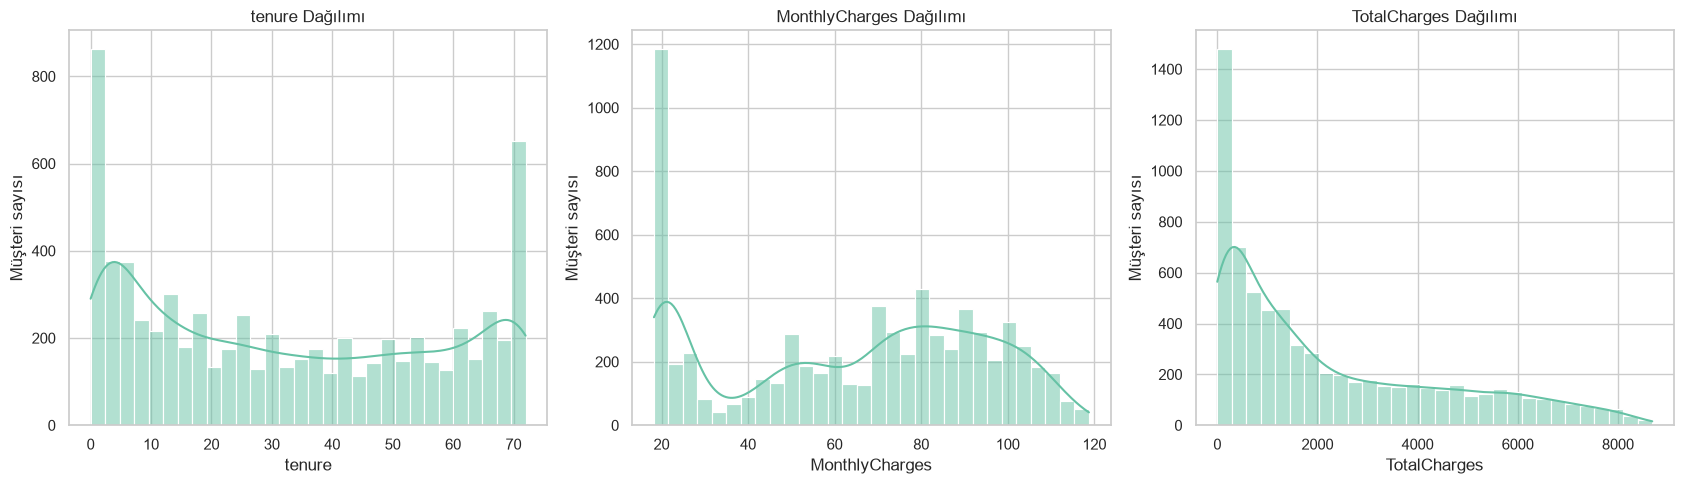

In [198]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for column, ax in zip(numeric_columns, axes):
    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{column} Dağılımı")
    ax.set_xlabel(column)
    ax.set_ylabel("Müşteri sayısı")

plt.tight_layout()
plt.show()

Tenure dağılımında hem yeni hem de uzun süredir şirkette olan müşteri grupları görülüyor. Aylık ve toplam ödeme değişkenleri eşit bir dağılıma sahip değil ve özellikle toplam ödeme tutarı abonelik süresinden etkilenmektedir.

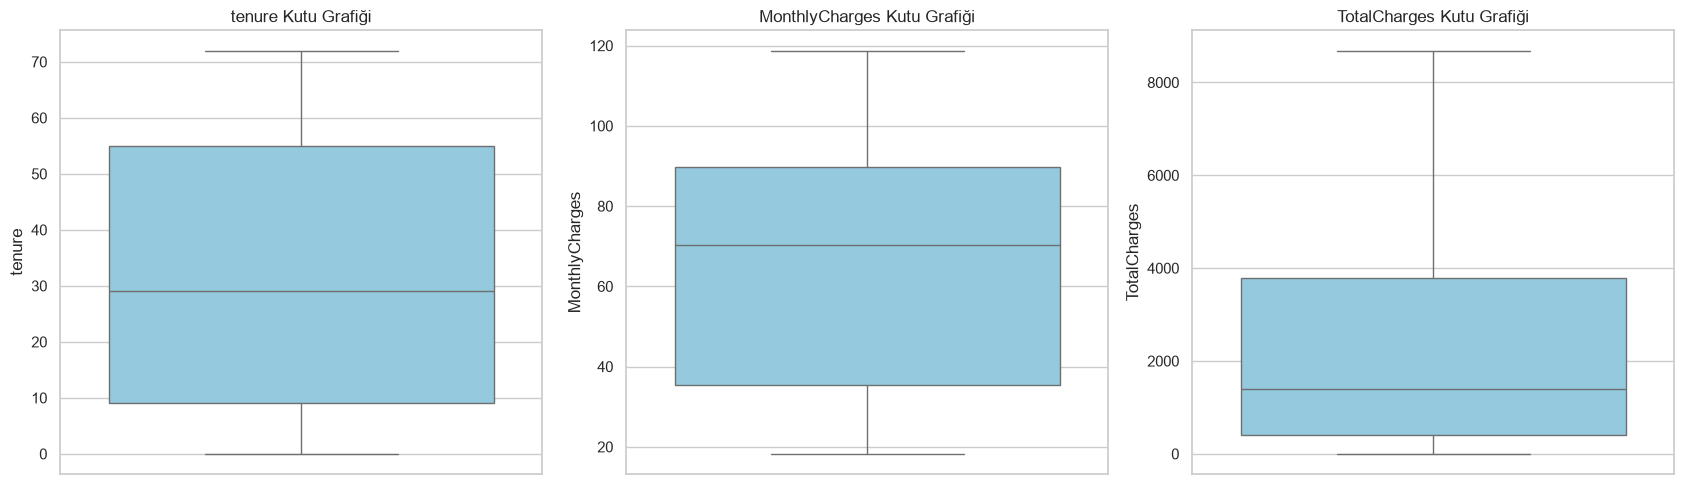

In [199]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for column, ax in zip(numeric_columns, axes):
    sns.boxplot(
        data=df,
        y=column,
        color="skyblue",
        ax=ax
    )

    ax.set_title(f"{column} Kutu Grafiği")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

Sayısal değişkenlerde belirgin aykırı değerler bulunmamaktadır.

In [200]:
categorical_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

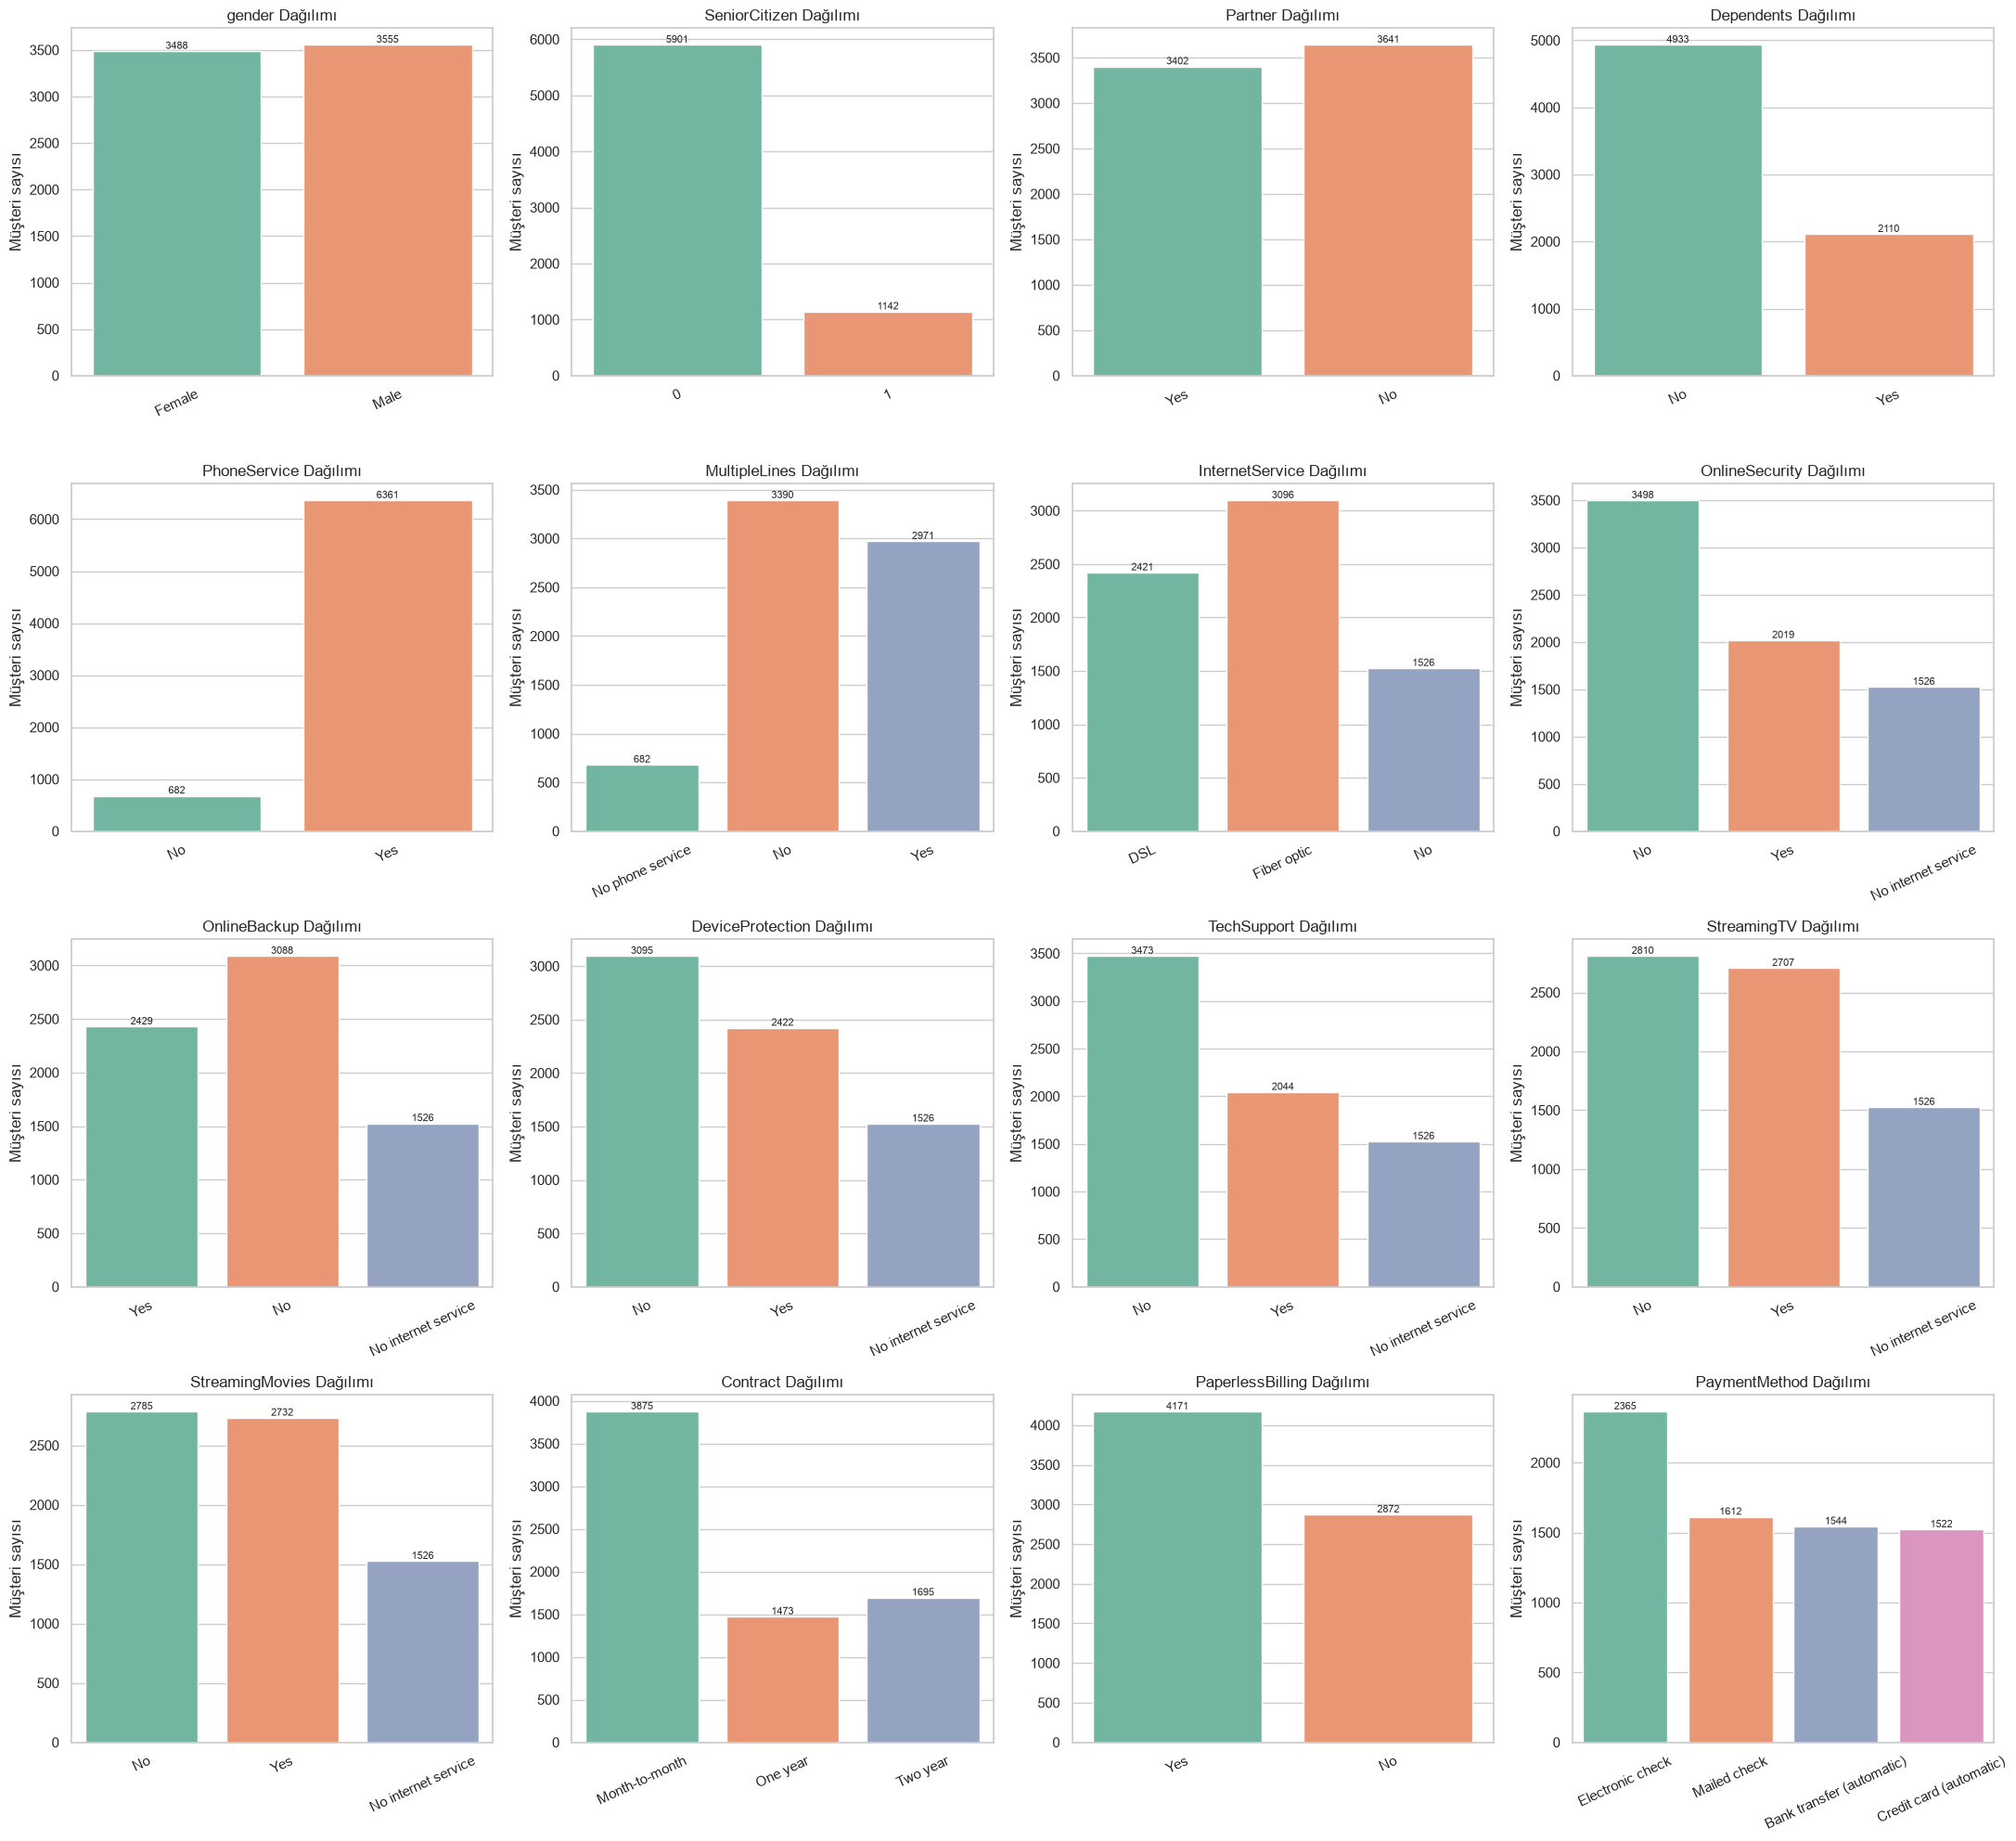

In [201]:
fig, axes = plt.subplots(4, 4, figsize=(22, 20))

axes = axes.flatten()

for column, ax in zip(categorical_columns, axes):
    sns.countplot(
        data=df,
        x=column,
        hue=column,
        legend=False,
        ax=ax
    )

    ax.set_title(f"{column} Dağılımı")
    ax.set_xlabel("")
    ax.set_ylabel("Müşteri sayısı")
    ax.tick_params(axis="x", rotation=25)

    for container in ax.containers:
        ax.bar_label(container, fontsize=8)

plt.tight_layout()
plt.show()

`SeniorCitizen` kolonunda 0 değeri müşterinin senior citizen grubunda
olmadığını, 1 değeri ise bu grupta olduğunu ifade etmektedir

In [202]:
def calculate_churn_rate(data, column):
    churn_rate = (
        data.groupby(column, observed=False)["Churn"]
        .apply(lambda values: values.eq("Yes").mean() * 100)
        .sort_values(ascending=False)
        .reset_index(name="ChurnRate")
    )

    return churn_rate

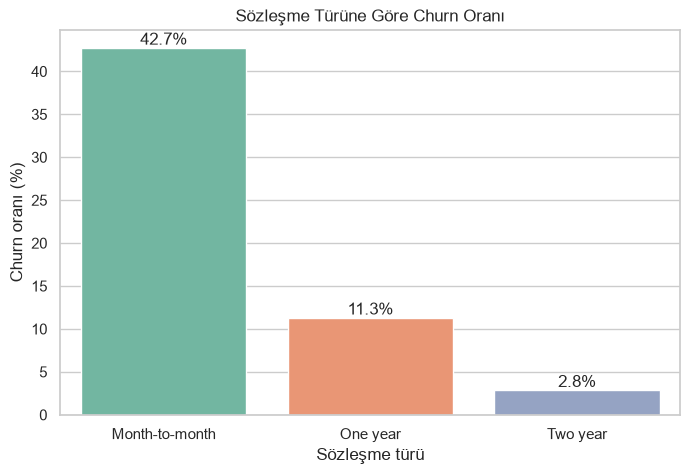

In [203]:
contract_churn = calculate_churn_rate(df, "Contract")

plt.figure(figsize=(8,5))
ax = sns.barplot(
    data=contract_churn,
    x="Contract",
    y="ChurnRate",
    hue="Contract",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Sözleşme Türüne Göre Churn Oranı")
plt.xlabel("Sözleşme türü")
plt.ylabel("Churn oranı (%)")
plt.show()

Aylık sözleşmeye sahip müşterilerin churn oranı, bir veya iki yıllık sözleşmeye sahip müşterilere göre daha yüksek. Uzun süreli sözleşmeler ile müşteri bağlılığı arasında bir ilişki olabileceği görülmekte.

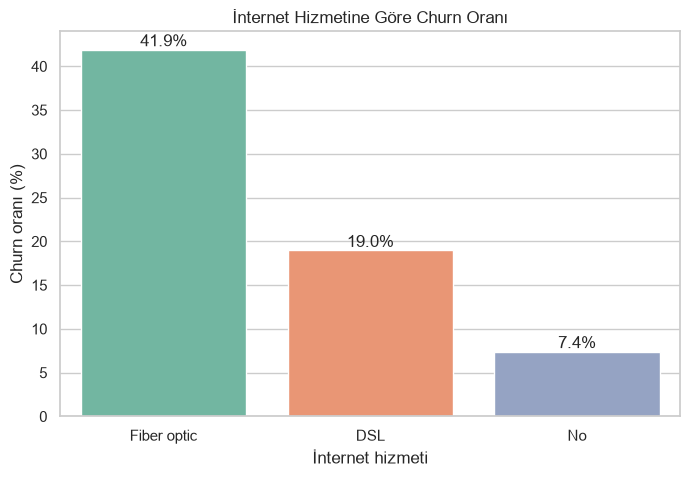

In [204]:
internet_churn = calculate_churn_rate(
    df,
    "InternetService"
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=internet_churn,
    x="InternetService",
    y="ChurnRate",
    hue="InternetService",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("İnternet Hizmetine Göre Churn Oranı")
plt.xlabel("İnternet hizmeti")
plt.ylabel("Churn oranı (%)")
plt.show()

Fiber optik internet kullanan müşterilerin churn oranının diğer gruplara göre daha yüksek olduğu görülmekte. Bununla birlikte bu ilişki fiyat gibi başka değişkenlerden de etkilenmiş olabilir. 

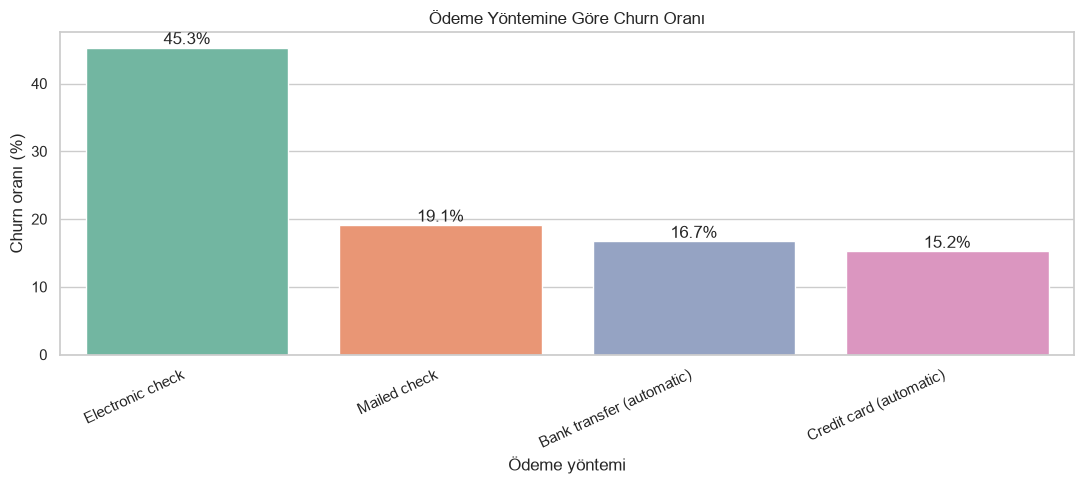

In [205]:
payment_churn = calculate_churn_rate(
    df,
    "PaymentMethod"
)

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=payment_churn,
    x="PaymentMethod",
    y="ChurnRate",
    hue="PaymentMethod",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Ödeme Yöntemine Göre Churn Oranı")
plt.xlabel("Ödeme yöntemi")
plt.ylabel("Churn oranı (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Elektronik çek kullanan müşterilerin churn oranının diğer ödeme yöntemlerini kullanan müşterilere göre daha yüksek olduğu görülmektedir.

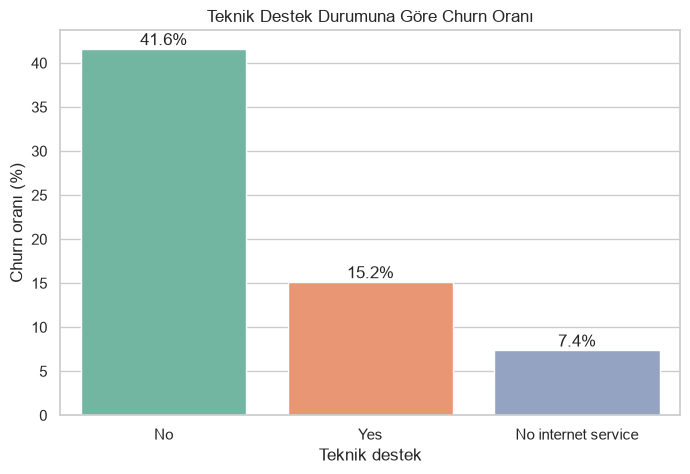

In [206]:
support_churn = calculate_churn_rate(
    df,
    "TechSupport"
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=support_churn,
    x="TechSupport",
    y="ChurnRate",
    hue="TechSupport",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Teknik Destek Durumuna Göre Churn Oranı")
plt.xlabel("Teknik destek")
plt.ylabel("Churn oranı (%)")
plt.show()

Teknik destek almayan müşterilerin churn oranının teknik destek alan müşterilere göre daha yüksek olduğu görülmektedir.

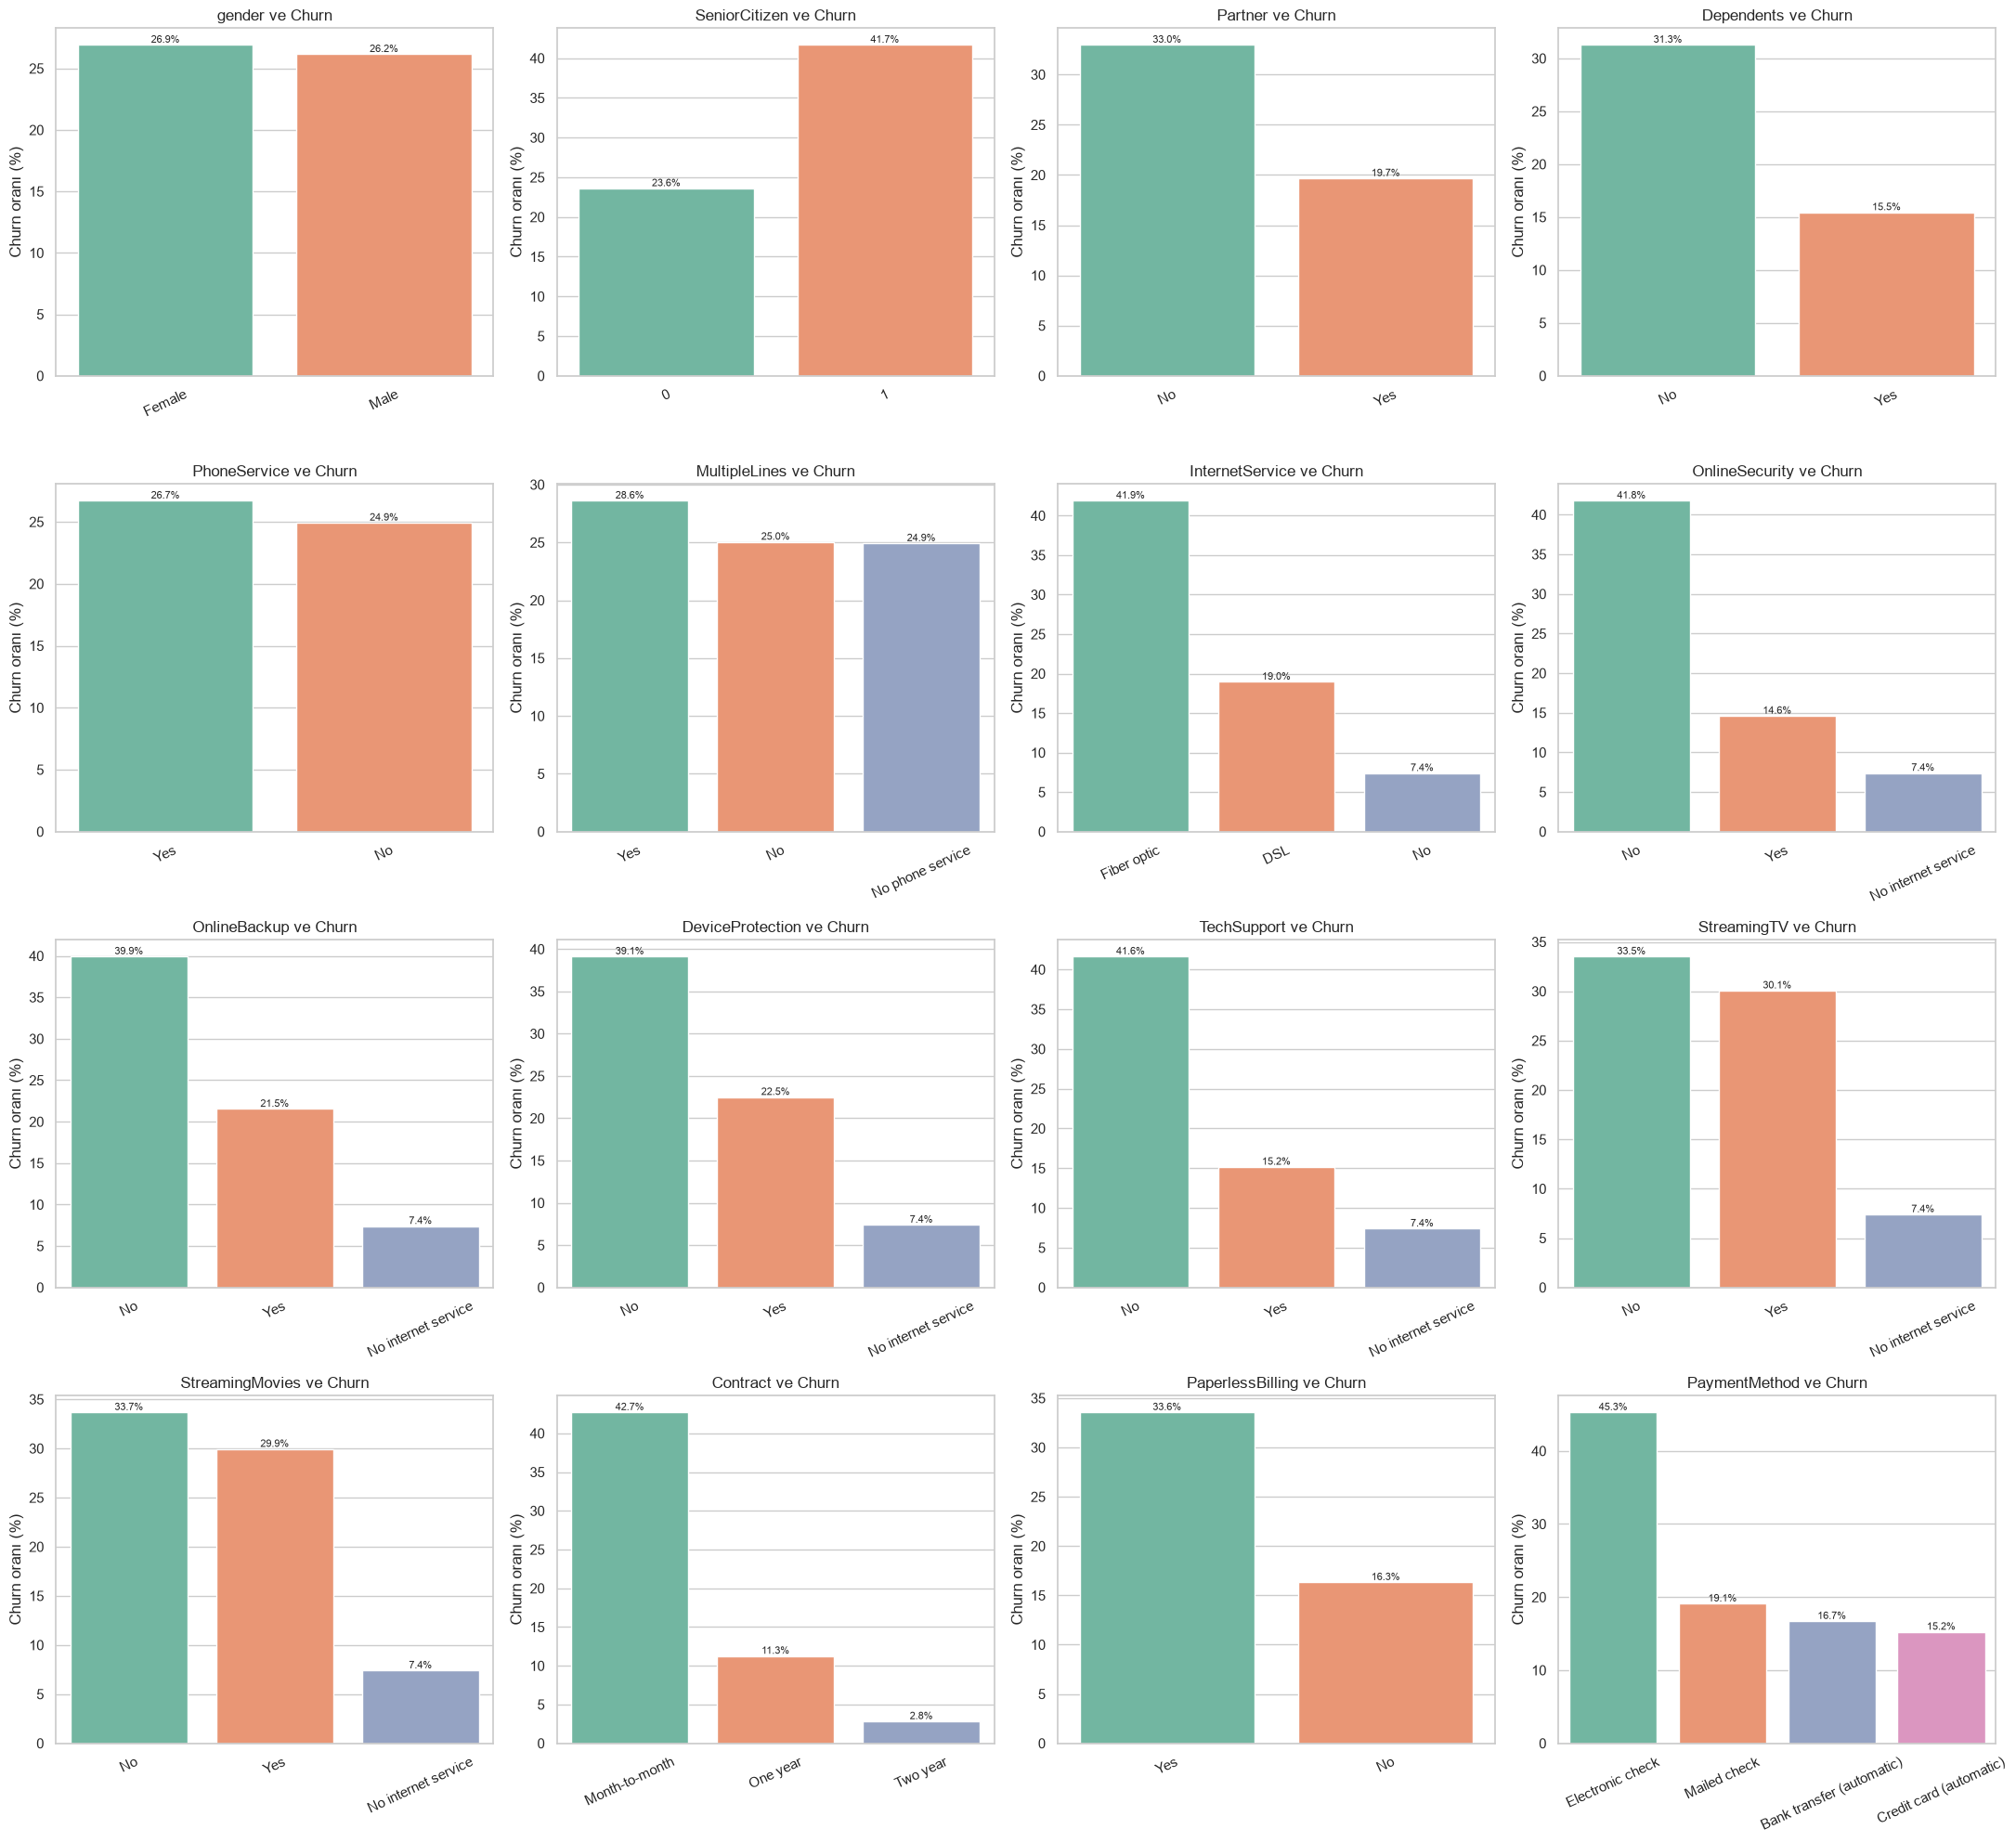

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(22, 20))
axes = axes.flatten()

for column, ax in zip(categorical_columns, axes):
    rates = calculate_churn_rate(df, column)

    sns.barplot(
        data=rates,
        x=column,
        y="ChurnRate",
        hue=column,
        legend=False,
        ax=ax
    )

    ax.set_title(f"{column} ve Churn")
    ax.set_xlabel("")
    ax.set_ylabel("Churn oranı (%)")
    ax.tick_params(axis="x", rotation=25)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            fontsize=8
        )

plt.tight_layout()
plt.show()

Kategorik değişkenlerin churn oranları incelendiğinde aylık sözleşmeye,
fiber optik internete ve elektronik çek ödeme yöntemine sahip
müşterilerde churn oranının daha yüksek olduğu görülmektedir. Teknik
destek ve çevrim içi güvenlik hizmeti almayan müşterilerde de churn
oranı daha yüksektir.

Uzun süreli sözleşmeye sahip, otomatik ödeme kullanan ve teknik destek
hizmeti alan müşterilerde churn oranının daha düşük olduğu
gözlemlenmiştir

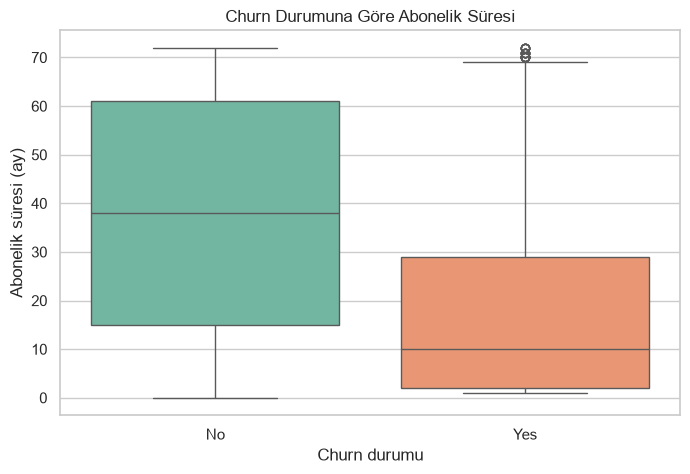

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    legend=False
)

plt.title("Churn Durumuna Göre Abonelik Süresi")
plt.xlabel("Churn durumu")
plt.ylabel("Abonelik süresi (ay)")
plt.show()

Aboneliğini iptal eden müşterilerin abonelik sürelerinin genel olarak daha kısa olduğu görülmekte. Bu sonuç, şirkete yeni katılan müşterilerin churn riskinin daha yüksek olabileceğini göstermektedir.

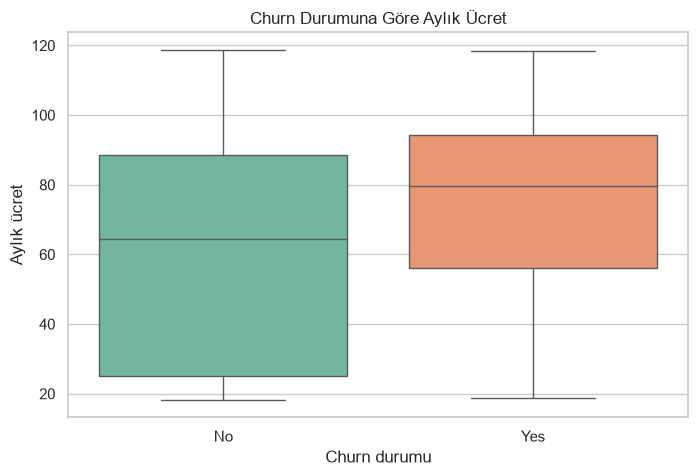

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    legend=False
)

plt.title("Churn Durumuna Göre Aylık Ücret")
plt.xlabel("Churn durumu")
plt.ylabel("Aylık ücret")
plt.show()

In [ ]:
Churn eden müşterilerin aylık ücretlerinin genel olarak daha yüksek olduğu görülmektedir. # type: ignore

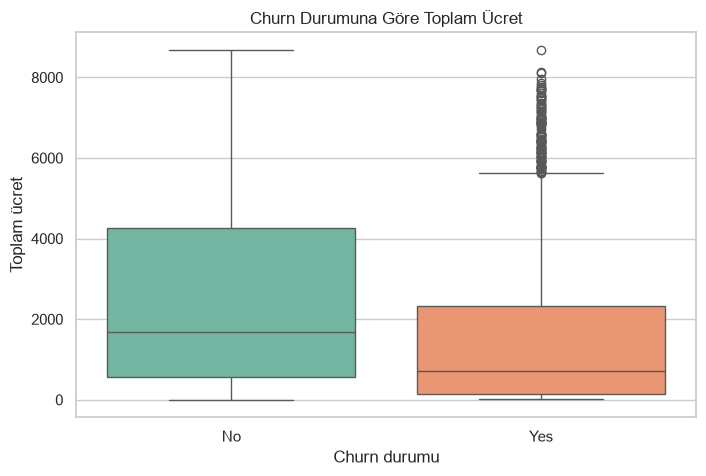

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges",
    hue="Churn",
    legend=False
)

plt.title("Churn Durumuna Göre Toplam Ücret")
plt.xlabel("Churn durumu")
plt.ylabel("Toplam ücret")
plt.show()

Churn eden müşterilerin toplam ödeme tutarlarının genellikle daha düşük olduğu görülmektedir. Ancak bu durum churn eden müşterilerin abonelik sürelerinin daha kısa olmasıyla ilişkili olabilir; bu nedenle toplam ücret tek başına değerlendirilmemeli.

In [ ]:
correlation_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()

correlation_df["ChurnNumeric"] = (
    df["Churn"].map({"No": 0, "Yes": 1})
)

correlation_matrix = correlation_df.corr()

correlation_matrix

,tenure,MonthlyCharges,TotalCharges,ChurnNumeric
tenure,1.000000,0.247900,0.826178,-0.352229
MonthlyCharges,0.247900,1.000000,0.651174,0.193356
TotalCharges,0.826178,0.651174,1.000000,-0.198324
ChurnNumeric,-0.352229,0.193356,-0.198324,1.000000


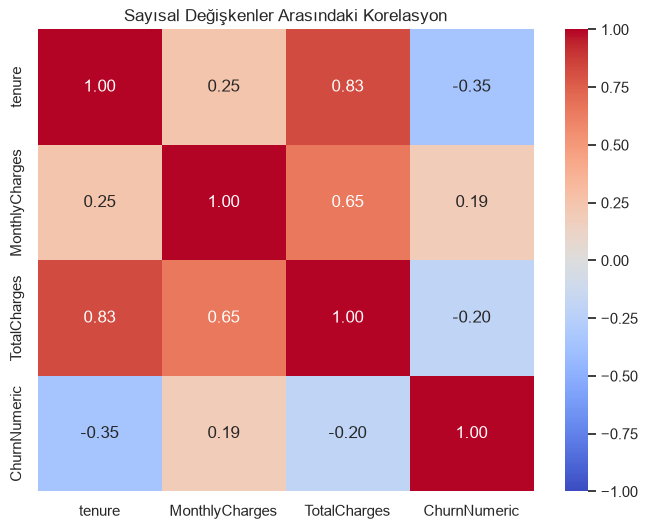

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Sayısal Değişkenler Arasındaki Korelasyon")
plt.show()

In [ ]:
Abonelik süresi ile toplam ücret arasında güçlü ve pozitif bir ilişki bulunmaktadır. Churn ile abonelik süresi arasındaki negatif ilişki, uzun süredir müşteri olan kişilerin ayrılma eğiliminin daha düşük olabileceğini göstermektedir.  # type: ignore